# Ionic Conductivity ML — Day 1: Problem and Data Contract

## Project goal

Develop a validated neural network that predicts lithium-ion conductivity from composition, crystal structure, temperature, and documented measurement conditions. The four-week ML phase will also identify stable, physically meaningful variables and representative materials for later DFT, molecular-dynamics, and phase-field studies; no simulations are performed during this phase.

### Day 1 outcome

This concise notebook freezes the prediction target, unit convention, row definition, required metadata, validation groups, and neural-network design before conductivity data are collected or modeled. The Materials Project setup is retained to audit available crystal structures and descriptors, but no prior voltage model is part of this deliverable.


## 1. Modeling decisions

| Decision | Day 1 specification |
|---|---|
| Mobile ion | Li$^+$ only for model v1 |
| Working material scope | Inorganic solid-state lithium-ion conductors |
| Predicted property | Ionic conductivity, excluding electronic and total conductivity |
| Canonical unit | S/cm |
| Model target | $\log_{10}(\sigma_{\mathrm{ion}}/\mathrm{S\,cm^{-1}})$ |
| Temperature strategy | Temperature-conditioned model, with 298.15 K used for standard reporting |
| Unit of observation | One conductivity value for one resolved material phase at one temperature and condition |
| Primary validation group | Material/structure identity; all temperatures for one material remain together |
| Strong generalization test | Chemical systems excluded entirely from training |
| Initial predictor scope | Composition, crystal structure, temperature, and non-outcome measurement metadata |
| Intended use | Dataset analysis, prediction, uncertainty estimation, and variable selection—not autonomous materials decisions |

**Scope rule:** if the conductivity dataset includes polymers, liquids, composites, or sodium conductors, they will be separated from model v1 rather than silently mixed with inorganic Li-ion conductors.

In [1]:
from __future__ import annotations

import json
import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/battery_ml_matplotlib")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
RAW_MP_PATH = ROOT / "data/raw/mp_li_insertion_electrodes.json"
MP_FEATURE_PATH = ROOT / "data/processed/li_insertion_electrodes_features.csv"
FIGURE_DIR = ROOT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Figure system adapted from the supplied report and the official UIUC palette.
ILLINI_BLUE = "#13294B"
ILLINI_ORANGE = "#FF5F05"
ILLINI_STORM = "#707372"
ILLINI_STORM_LIGHT = "#C6C7C6"


def apply_report_style():
    plt.rcParams.update({
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.labelsize": 10,
        "axes.linewidth": 1.0,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "legend.frameon": False,
        "grid.color": ILLINI_STORM_LIGHT,
        "grid.linewidth": 0.7,
        "grid.alpha": 0.85,
        "lines.linewidth": 1.5,
    })


def finish_axis(axis, grid_axis="y"):
    axis.grid(True, axis=grid_axis)
    axis.set_axisbelow(True)
    axis.tick_params(direction="out", length=4, width=0.9)


def save_report_figure(figure, filename):
    output = FIGURE_DIR / filename
    figure.savefig(output, dpi=300, bbox_inches="tight", facecolor="white")
    print("Saved figure:", output)


apply_report_style()

# Keep the existing MP setup, but make both local caches optional so this
# Day 1 notebook remains runnable when distributed with only its deliverables.
raw_cache_available = RAW_MP_PATH.exists()
feature_cache_available = MP_FEATURE_PATH.exists()
if raw_cache_available:
    mp_records = pd.DataFrame(json.loads(RAW_MP_PATH.read_text(encoding="utf-8")))
elif feature_cache_available:
    mp_records = pd.read_csv(MP_FEATURE_PATH)
else:
    mp_records = pd.DataFrame()

conductivity_fields = [
    column for column in mp_records.columns
    if "conduct" in column.lower() or "sigma" in column.lower()
]
unique_chemsys = (
    mp_records["chemsys"].nunique()
    if "chemsys" in mp_records.columns
    else 0
)

current_data_audit = pd.Series(
    {
        "raw_MP_cache_available": raw_cache_available,
        "processed_MP_cache_available": feature_cache_available,
        "available_MP_records": len(mp_records),
        "unique_MP_chemical_systems": unique_chemsys,
        "conductivity_fields_in_current_MP_cache": len(conductivity_fields),
    },
    name="value",
)
display(current_data_audit.to_frame())
print("Matching conductivity fields:", conductivity_fields or "none")
print(
    "Decision: MP supplies candidate structures and descriptors; "
    "a separate ionic-conductivity label table is required."
)


,value
raw_MP_cache_available,True
processed_MP_cache_available,True
available_MP_records,2774
unique_MP_chemical_systems,670
conductivity_fields_in_current_MP_cache,0


Matching conductivity fields: none
Decision: MP supplies candidate structures and descriptors; a separate ionic-conductivity label table is required.


## 2. Target definition

Conductivity usually spans several orders of magnitude, so the regression target is

$$
y_i=\log_{10}\!\left(\frac{\sigma_{\mathrm{ion},i}}{1\ \mathrm{S\,cm^{-1}}}\right).
$$

The prediction is converted back to physical units using

$$
\widehat{\sigma}_{\mathrm{ion},i}=10^{\hat y_i}\ \mathrm{S\,cm^{-1}}.
$$

An MAE of $m$ in log space corresponds approximately to a multiplicative error factor of $10^m$. For example, MAE $=0.5$ means a typical error of roughly a factor of 3.2.

Temperature is retained explicitly:

$$
\hat y=f(\text{composition},\text{structure},T,\text{documented conditions}).
$$

This avoids treating measurements made at different temperatures as if they represented the same target. Predictions will later be compared at 298.15 K, but measured values will not be extrapolated to room temperature unless a documented Arrhenius fit is available.

In [2]:
TARGET_COLUMN = "log10_sigma_S_cm"
REFERENCE_TEMPERATURE_K = 298.15
MOBILE_ION = "Li"
MATERIAL_SCOPE = "inorganic solid-state lithium-ion conductor"

DATA_SCHEMA = [
    ("record_id", "string", "Unique source-record identifier", True),
    ("material_key", "string", "Canonical material/phase identifier", True),
    ("mp_id", "string", "Materials Project ID when a confident match exists", False),
    ("formula", "string", "Reported chemical formula", True),
    ("chemsys", "string", "Hyphen-separated chemical system", True),
    ("structure_id", "string", "Structure or polymorph identifier", False),
    ("phase", "string", "Reported phase or space group", False),
    ("mobile_ion", "string", "Li for model v1", True),
    ("material_class", "string", "Electrolyte/material family", True),
    ("conductivity_value", "float", "Positive value in the reported unit", True),
    ("conductivity_unit", "string", "Unit before normalization", True),
    ("temperature_K", "float", "Measurement or simulation temperature in kelvin", True),
    ("conductivity_type", "string", "Must explicitly identify ionic conductivity", True),
    ("label_origin", "string", "experimental, MD, or other computed source", True),
    ("measurement_method", "string", "Impedance, MD, or other method", False),
    ("uncertainty", "float", "Reported uncertainty when available", False),
    ("reference", "string", "DOI, database record, or source citation", True),
    ("notes", "string", "Processing, density, grain, or quality notes", False),
]

schema_df = pd.DataFrame(
    DATA_SCHEMA,
    columns=["column", "dtype", "definition", "required"],
)
display(schema_df)

,column,dtype,definition,required
0,record_id,string,Unique source-record identifier,True
1,material_key,string,Canonical material/phase identifier,True
2,mp_id,string,Materials Project ID when a confident match ex...,False
3,formula,string,Reported chemical formula,True
4,chemsys,string,Hyphen-separated chemical system,True
5,structure_id,string,Structure or polymorph identifier,False
6,phase,string,Reported phase or space group,False
7,mobile_ion,string,Li for model v1,True
8,material_class,string,Electrolyte/material family,True
9,conductivity_value,float,Positive value in the reported unit,True


## 3. Neural-network model: physics-informed crystal graph network

### Model in battery language

The primary algorithm is a **Physics-Informed Arrhenius Crystal Graph Neural Network (PI-ACGNN)**. It reads a periodic crystal structure, learns which local atomic environments support lithium transport, and converts the learned material representation into conductivity at a specified temperature. A pretrained encoder such as CHGNet is the initial choice; M3GNet and ALIGNN are transfer-learning alternatives if they fit the final data better.

The neural-network comparison is deliberately focused: a composition-only multilayer perceptron (MLP) tests what chemistry alone can learn, an unconstrained crystal graph neural network tests the value of structure, and PI-ACGNN tests whether adding transport physics improves reliability.

### What is a crystal graph layer?

A crystal graph is $\mathcal G=(\mathcal V,\mathcal E)$: each node $v\in\mathcal V$ is an atom and each periodic edge $(u,v)\in\mathcal E$ is a neighboring atomic pair described by distance and, where available, angle information. At layer $\ell$, the network collects messages from each atom's neighbors and updates its hidden state:

$$
\mathbf m_v^{(\ell)}=\sum_{u\in\mathcal N(v)}
\phi_\ell\!\left(\mathbf h_v^{(\ell)},\mathbf h_u^{(\ell)},\mathbf e_{uv}\right),
\qquad
\mathbf h_v^{(\ell+1)}=psi_\ell\!\left(\mathbf h_v^{(\ell)},\mathbf m_v^{(\ell)}\right).
$$

Here, $\phi_\ell$ and $\psi_\ell$ are small trainable neural networks, $\mathbf e_{uv}$ describes local geometry, and $\mathcal N(v)$ is the periodic neighbor list. Pooling the final atom states gives one material vector,

$$
\mathbf h_{\mathrm{crystal}}=\operatorname{Pool}\!\left(\{\mathbf h_v^{(L)}\}_{v\in\mathcal V}\right),
$$

which is combined with non-outcome metadata before the prediction heads.

### Physics-informed prediction head

Two heads estimate a positive activation energy and a conductivity prefactor:

$$
\widehat{E}_a=\operatorname{softplus}\!\left(g_E(\mathbf h_{\mathrm{crystal}})\right)>0,
\qquad
\widehat{\log_{10}\sigma_0}=g_0(\mathbf h_{\mathrm{crystal}}).
$$

The initial model imposes the Arrhenius relation directly:

$$
\widehat{\log_{10}\sigma(T)}=
\widehat{\log_{10}\sigma_0}
-\frac{\widehat{E}_a}{k_{\mathrm B}T\ln 10}.
$$

If validation reveals systematic non-Arrhenius behavior, a small correction $r_\theta(\mathbf h,T)$ may be added. It must remain regularized toward zero and improve unseen-material performance:

$$
\hat y(T)=\widehat{\log_{10}\sigma_0}
-\frac{\widehat{E}_a}{k_{\mathrm B}T\ln 10}
+r_\theta(\mathbf h,T).
$$

The loss combines prediction fit, residual control, and physically expected temperature behavior:

$$
\mathcal L=\mathcal L_{\mathrm{NLL}}
+\lambda_r\lVert r_\theta\rVert_2^2
+\lambda_T\sum_i\max\!\left(0,-\frac{\partial \hat y_i}{\partial T}\right)^2.
$$

$\mathcal L_{\mathrm{NLL}}$ is a heteroscedastic Gaussian negative log likelihood, so the network learns data-dependent uncertainty. A multi-seed deep ensemble estimates model uncertainty.

### Data-efficient training plan

1. Train a composition-only MLP as the neural baseline.
2. Freeze the pretrained crystal encoder and train only the conductivity and uncertainty heads.
3. Compare the unconstrained graph network with the Arrhenius-constrained version on identical grouped splits.
4. Fine-tune upper encoder layers only if the dataset is large enough and validation improves.
5. Select PI-ACGNN only if it improves unseen-chemistry error, uncertainty calibration, and temperature consistency.

This remains an empirical predictor: pretraining does not guarantee accurate defect or migration-barrier physics. Primary references: [CHGNet](https://doi.org/10.1038/s42256-023-00716-3), [M3GNet](https://doi.org/10.1038/s43588-022-00349-3), [ALIGNN](https://doi.org/10.1038/s41524-021-00650-1), and [Arrhenius-constrained ionic-conductivity ML](https://doi.org/10.1016/j.jnoncrysol.2025.123497).


In [3]:
ADVANCED_MODEL_SPEC = pd.Series(
    {
        "primary_model": "Physics-Informed Arrhenius Crystal GNN (PI-ACGNN)",
        "structure_encoder": "pretrained CHGNet; evaluate M3GNet/ALIGNN if needed",
        "physics_constraint": "Arrhenius conductivity-temperature relation",
        "latent_outputs": "positive activation energy and log10 prefactor",
        "uncertainty": "heteroscedastic head plus multi-seed deep ensemble",
        "neural_baselines": "composition MLP and unconstrained crystal GNN",
        "training_strategy": "freeze encoder, train heads, then selective fine-tuning",
        "selection_rule": "adopt only if unseen-chemistry accuracy and calibration improve",
    },
    name="neural-network decision",
)
display(ADVANCED_MODEL_SPEC.to_frame())


,neural-network decision
primary_model,Physics-Informed Arrhenius Crystal GNN (PI-ACGNN)
structure_encoder,pretrained CHGNet; evaluate M3GNet/ALIGNN if n...
physics_constraint,Arrhenius conductivity-temperature relation
latent_outputs,positive activation energy and log10 prefactor
uncertainty,heteroscedastic head plus multi-seed deep ense...
neural_baselines,composition MLP and unconstrained crystal GNN
training_strategy,"freeze encoder, train heads, then selective fi..."
selection_rule,adopt only if unseen-chemistry accuracy and ca...


Saved figure: /Users/zhy/Downloads/battery_ml_starter/figures/figure_01_physics_informed_conductivity_model.png


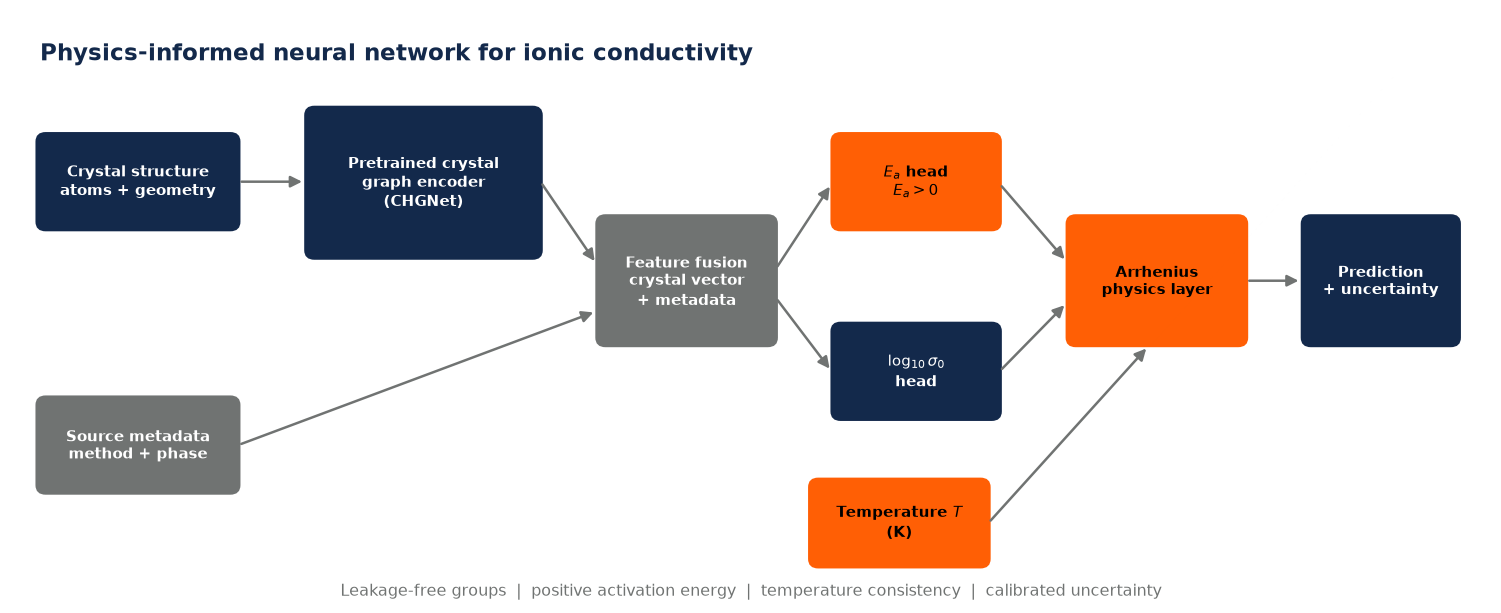

In [4]:
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch


def architecture_box(axis, xy, width, height, text, facecolor, textcolor="white"):
    box = FancyBboxPatch(
        xy, width, height,
        boxstyle="round,pad=0.03,rounding_size=0.08",
        linewidth=1.4, edgecolor=facecolor, facecolor=facecolor,
    )
    axis.add_patch(box)
    axis.text(
        xy[0] + width / 2, xy[1] + height / 2, text,
        ha="center", va="center", color=textcolor,
        fontsize=9.2, fontweight="bold", linespacing=1.22,
    )


def architecture_arrow(axis, start, end):
    axis.add_patch(FancyArrowPatch(
        start, end, arrowstyle="-|>", mutation_scale=14,
        linewidth=1.5, color=ILLINI_STORM,
        connectionstyle="arc3,rad=0.0",
    ))


fig, axis = plt.subplots(figsize=(12.4, 5.0), constrained_layout=True)
axis.set_xlim(0, 13.2)
axis.set_ylim(0, 5.6)
axis.axis("off")

axis.text(
    0.25, 5.3, "Physics-informed neural network for ionic conductivity",
    color=ILLINI_BLUE, fontsize=14, fontweight="bold", va="top",
)

architecture_box(axis, (0.25, 3.55), 1.75, 0.86, "Crystal structure\natoms + geometry", ILLINI_BLUE)
architecture_box(axis, (0.25, 1.05), 1.75, 0.86, "Source metadata\nmethod + phase", ILLINI_STORM)
architecture_box(axis, (7.15, 0.35), 1.55, 0.78, "Temperature $T$\n(K)", ILLINI_ORANGE, "black")

architecture_box(axis, (2.65, 3.28), 2.05, 1.38, "Pretrained crystal\ngraph encoder\n(CHGNet)", ILLINI_BLUE)
architecture_box(axis, (5.25, 2.45), 1.55, 1.18, "Feature fusion\ncrystal vector\n+ metadata", ILLINI_STORM)
architecture_box(axis, (7.35, 3.55), 1.45, 0.86, "$E_a$ head\n$E_a>0$", ILLINI_ORANGE, "black")
architecture_box(axis, (7.35, 1.75), 1.45, 0.86, "$\\log_{10}\\sigma_0$\nhead", ILLINI_BLUE)
architecture_box(axis, (9.45, 2.45), 1.55, 1.18, "Arrhenius\nphysics layer", ILLINI_ORANGE, "black")
architecture_box(axis, (11.55, 2.45), 1.35, 1.18, "Prediction\n+ uncertainty", ILLINI_BLUE)

architecture_arrow(axis, (2.02, 3.98), (2.62, 3.98))
architecture_arrow(axis, (4.72, 3.98), (5.22, 3.20))
architecture_arrow(axis, (2.02, 1.48), (5.22, 2.75))
architecture_arrow(axis, (6.82, 3.15), (7.32, 3.96))
architecture_arrow(axis, (6.82, 2.88), (7.32, 2.18))
architecture_arrow(axis, (8.82, 3.96), (9.42, 3.22))
architecture_arrow(axis, (8.82, 2.18), (9.42, 2.83))
architecture_arrow(axis, (8.72, 0.74), (10.15, 2.42))
architecture_arrow(axis, (11.02, 3.04), (11.52, 3.04))

axis.text(
    6.6, 0.05,
    "Leakage-free groups  |  positive activation energy  |  "
    "temperature consistency  |  calibrated uncertainty",
    color=ILLINI_STORM, fontsize=9.3, ha="center",
)

save_report_figure(fig, "figure_01_physics_informed_conductivity_model.png")
plt.show()


**Figure 1.** Proposed PI-ACGNN workflow. The crystal graph encoder learns a structural representation, which is fused with documented non-outcome metadata. Separate neural heads estimate a positive activation energy and conductivity prefactor; the Arrhenius layer combines them with temperature to predict log conductivity, while the ensemble reports uncertainty. The neural comparisons use identical leakage-free material and chemical-system splits.


## 4. Label normalization and acceptance checks

Every source value must retain its original value and unit. The normalization step creates new canonical columns rather than overwriting source data.

Accepted conductivity units in the first ingestion pass are S/cm, mS/cm, µS/cm, S/m, and mS/m. Resistivity values must be identified and converted separately using $\sigma=1/\rho$; they must never be passed to the conductivity converter as if they were conductivity.

In [5]:
UNIT_TO_S_CM = {
    "S/cm": 1.0,
    "mS/cm": 1e-3,
    "uS/cm": 1e-6,
    "µS/cm": 1e-6,
    "S/m": 1e-2,
    "mS/m": 1e-5,
}

REQUIRED_COLUMNS = [row[0] for row in DATA_SCHEMA if row[3]]


def conductivity_to_s_cm(value: float, unit: str) -> float:
    # Convert a positive conductivity value to S/cm.
    if unit not in UNIT_TO_S_CM:
        raise ValueError(f"Unsupported conductivity unit: {unit!r}")
    value = float(value)
    if not np.isfinite(value) or value <= 0:
        raise ValueError("Conductivity must be finite and strictly positive.")
    return value * UNIT_TO_S_CM[unit]


def material_group_key(row: pd.Series) -> str:
    # Keep polymorphs and repeated temperatures together during validation.
    for column in ("structure_id", "mp_id", "material_key"):
        value = row.get(column)
        if pd.notna(value) and str(value).strip():
            return str(value).strip()
    return f"{row.get('formula', 'unknown')}|{row.get('phase', 'unknown')}"


def prepare_conductivity_labels(frame: pd.DataFrame) -> pd.DataFrame:
    # Validate source labels and create canonical ML columns.
    missing = sorted(set(REQUIRED_COLUMNS) - set(frame.columns))
    if missing:
        raise KeyError(f"Missing required source columns: {missing}")

    prepared = frame.copy()
    prepared["sigma_S_cm"] = [
        conductivity_to_s_cm(value, unit)
        for value, unit in zip(
            prepared["conductivity_value"],
            prepared["conductivity_unit"],
        )
    ]
    prepared["temperature_K"] = pd.to_numeric(
        prepared["temperature_K"], errors="raise"
    )
    if not prepared["temperature_K"].between(100, 2000).all():
        raise ValueError("Review temperatures outside the broad 100–2000 K audit range.")
    if not prepared["mobile_ion"].eq(MOBILE_ION).all():
        raise ValueError("Model v1 accepts Li-ion records only.")
    if not prepared["conductivity_type"].str.lower().eq("ionic").all():
        raise ValueError("Non-ionic or ambiguous conductivity records must be separated.")

    prepared[TARGET_COLUMN] = np.log10(prepared["sigma_S_cm"])
    prepared["group_material"] = prepared.apply(material_group_key, axis=1)
    return prepared


intake_template = pd.DataFrame(columns=[row[0] for row in DATA_SCHEMA])
INTAKE_TEMPLATE_PATH = ROOT / "data/processed/ionic_conductivity_intake_template.csv"
INTAKE_TEMPLATE_PATH.parent.mkdir(parents=True, exist_ok=True)
intake_template.to_csv(INTAKE_TEMPLATE_PATH, index=False)
display(intake_template)
print("Saved Day 2 intake template:", INTAKE_TEMPLATE_PATH)

,record_id,material_key,mp_id,formula,chemsys,structure_id,phase,mobile_ion,material_class,conductivity_value,conductivity_unit,temperature_K,conductivity_type,label_origin,measurement_method,uncertainty,reference,notes


Saved Day 2 intake template: /Users/zhy/Downloads/battery_ml_starter/data/processed/ionic_conductivity_intake_template.csv


## 5. Leakage-free validation contract

### Required splitting rules

1. All temperatures, repeat measurements, and methods for one resolved material remain in the same fold through `group_material`.
2. The final generalization test holds out complete `chemsys` groups when the dataset is large enough.
3. Imputation, scaling, encoding, feature selection, and tuning are fitted only on training folds.
4. Duplicate literature records are resolved before splitting, not after.

### Variables excluded from the initial feature set

- Conductivity at another temperature for the same material
- Activation energy fitted from the same conductivity measurements
- Arrhenius intercept fitted from the same measurements
- Any manually assigned high/low-conductivity label
- Material identifiers or source identifiers
- Post hoc variables calculated using the target

Migration barriers or defect energies may later be evaluated in a separate enhanced model, but they will not be mixed into the composition-and-structure baseline without a clear availability and cost definition.

### Planned metrics

- MAE and RMSE in $\log_{10}(\mathrm{S/cm})$
- $R^2$
- Multiplicative error factor, $10^{\mathrm{MAE}}$
- Bootstrap confidence intervals grouped by material or chemical system
- Error by temperature range, chemical family, label origin, and applicability domain

In [6]:
DAY1_CONTRACT = pd.Series(
    {
        "target": TARGET_COLUMN,
        "canonical_unit": "S/cm",
        "reference_temperature_K": REFERENCE_TEMPERATURE_K,
        "mobile_ion": MOBILE_ION,
        "material_scope": MATERIAL_SCOPE,
        "row_definition": "one resolved material-phase/temperature/condition record",
        "primary_group": "group_material",
        "strong_holdout_group": "chemsys",
        "current_label_status": "not present in current MP insertion-electrode cache",
        "next_action": "ingest and audit an external ionic-conductivity label table",
    },
    name="Day 1 decision",
)
display(DAY1_CONTRACT.to_frame())

,Day 1 decision
target,log10_sigma_S_cm
canonical_unit,S/cm
reference_temperature_K,298.15
mobile_ion,Li
material_scope,inorganic solid-state lithium-ion conductor
row_definition,one resolved material-phase/temperature/condit...
primary_group,group_material
strong_holdout_group,chemsys
current_label_status,not present in current MP insertion-electrode ...
next_action,ingest and audit an external ionic-conductivit...


## 6. Figure standard for the ML project

All analytical figures will follow the supplied report layout and the official UIUC brand palette: Illini Blue (`#13294B`) and Illini Orange (`#FF5F05`) are dominant, with Storm gray used only for neutral baselines. Figures use a white background, bold panel labels, units on every quantitative axis, reference lines where decisions depend on a threshold or ideal value, legends outside dense data regions, and a complete caption stating the comparison and sample context. Figures are saved as 300-dpi PNG files in `figures/` with stable descriptive names.

## 7. Day 1 completion and Day 2 entry criteria

Day 1 is complete when the target, scope, units, temperature strategy, record definition, neural architecture, and validation groups are accepted. The current Materials Project cache contains useful structural information but no ionic-conductivity target, so model training must wait for a separate label table.

Day 2 begins by importing conductivity records into the schema above, preserving source provenance, normalizing units, resolving phases and duplicates, and measuring how many unique materials remain after quality filtering. Neural-network training begins only after that audit establishes a usable sample size and leakage-free material groups.
